# 06 — Entraînement du Convolutional Autoencoder
**Projet :** IndustrialDefect AI · **EPIC-03** · **US-03-03 (IDL-23)** · **ST-03-03-01 (IDL-31)**

Entraîne le CAE de référence (`cae_baseline.json`, US-03-01) sur les images **normales** du split
`train` d'une catégorie, avec suivi de la perte MSE sur `train` et `val` (manifestes US-02-03).
Le meilleur modèle est sélectionné sur la **validation**. Le test officiel n'est **jamais** utilisé ici.

Catégorie de cette exécution : définie par `CATEGORY` (cellule de configuration).

In [1]:
import shutil
import subprocess
import sys
from pathlib import Path

# ===== Code de l'équipe (dépôt GitHub) =====
REPO_URL = "https://github.com/MRdrissi/industrial-defect-ai.git"
REPO_BRANCH = "epic/03-convolutional-autoencoder"
REPO_DIR = Path("/kaggle/temp/industrial-defect-ai")   # /kaggle/temp : non sauvegardé dans l'Output

if REPO_DIR.exists():
    shutil.rmtree(REPO_DIR)
subprocess.run(
    ["git", "clone", "--quiet", "--depth", "1", "--branch", REPO_BRANCH, REPO_URL, str(REPO_DIR)],
    check=True,
)
GIT_COMMIT = subprocess.run(
    ["git", "-C", str(REPO_DIR), "rev-parse", "HEAD"],
    capture_output=True, text=True, check=True,
).stdout.strip()
sys.path.insert(0, str(REPO_DIR))

import torch
import torchvision
from src.models.convolutional_autoencoder import CAEConfig, ConvolutionalAutoencoder
from src.data.mvtec_dataset import MVTecDataset
from src.data.transforms import MVTecTransform
from src.data.dataloaders import create_dataloader

# ===== Vérification du GPU =====
assert torch.cuda.is_available(), "GPU non disponible : Session options → Accelerator → GPU T4 x2"
DEVICE = torch.device("cuda")

print("Branche     :", REPO_BRANCH)
print("Commit      :", GIT_COMMIT)
print("Python      :", sys.version.split()[0])
print("PyTorch     :", torch.__version__, "| torchvision :", torchvision.__version__)
print("GPU         :", torch.cuda.get_device_name(0), f"(x{torch.cuda.device_count()})")

Branche     : epic/03-convolutional-autoencoder
Commit      : 6a353b3a3a3aa7a4adfa69a6db120d5bec95d73b
Python      : 3.13.16
PyTorch     : 2.11.0+cu130 | torchvision : 0.26.0+cu130
GPU         : Tesla T4 (x2)


## Configuration et données
Hyperparamètres de l'exécution, architecture de référence `cae_baseline.json`,
et chargement des splits `train` / `val` depuis le manifeste figé (US-02-03).

In [2]:
import json
import random

import numpy as np

# ===== Configuration de l'exécution =====
CATEGORY = "transistor"      # transistor (US-03-03) ou hazelnut (US-03-04)
EPOCHS = 100
BATCH_SIZE = 16
LEARNING_RATE = 1e-3
NUM_WORKERS = 2

# ===== Architecture de référence (US-03-01) =====
CONFIG_FILE = REPO_DIR / "experiments" / "configs" / "cae_baseline.json"
cae_params = json.loads(CONFIG_FILE.read_text("utf-8"))["config"]
cae_params["image_size"] = tuple(cae_params["image_size"])
cae_params["encoder_channels"] = tuple(cae_params["encoder_channels"])
CAE_CONFIG = CAEConfig(**cae_params)
SEED = CAE_CONFIG.seed


def find_mvtec_root(base: Path = Path("/kaggle/input"), category: str = "bottle") -> Path:
    """Cherche le dossier parent qui contient <category>/train, test et ground_truth."""
    candidates = [
        p.parent for p in base.rglob(category)
        if p.is_dir() and all((p / d).is_dir() for d in ("train", "test", "ground_truth"))
    ]
    assert len(candidates) == 1, f"Racines MVTec trouvées : {candidates}"
    return candidates[0]


DATASET_ROOT = find_mvtec_root()
MANIFEST = REPO_DIR / "docs" / "data" / "us-02-03" / f"{CATEGORY}_manifest.csv"

# ===== Données : train et val uniquement (le test n'est jamais chargé) =====
transform = MVTecTransform(size=CAE_CONFIG.image_size, profile="cae")
train_ds = MVTecDataset(DATASET_ROOT, MANIFEST, CATEGORY, "train", transform)
val_ds = MVTecDataset(DATASET_ROOT, MANIFEST, CATEGORY, "val", transform)
assert all(s["label"] == 0 for s in train_ds.samples + val_ds.samples), "Anomalie dans train/val !"

train_loader = create_dataloader(train_ds, batch_size=BATCH_SIZE, num_workers=NUM_WORKERS, seed=SEED)
val_loader = create_dataloader(val_ds, batch_size=BATCH_SIZE, num_workers=NUM_WORKERS, seed=SEED)

batch = next(iter(train_loader))
print("Catégorie      :", CATEGORY)
print("Dataset        :", DATASET_ROOT)
print("Manifeste      :", MANIFEST.name)
print("Images train   :", len(train_ds), f"→ {len(train_loader)} lots de {BATCH_SIZE}")
print("Images val     :", len(val_ds), f"→ {len(val_loader)} lots")
print("Lot d'images   :", tuple(batch["image"].shape), batch["image"].dtype)
print("Plage pixels   :", round(batch["image"].min().item(), 3), "→", round(batch["image"].max().item(), 3))
print("Architecture   :", CAE_CONFIG)

Catégorie      : transistor
Dataset        : /kaggle/input/datasets/ipythonx/mvtec-ad
Manifeste      : transistor_manifest.csv
Images train   : 170 → 11 lots de 16
Images val     : 43 → 3 lots
Lot d'images   : (16, 3, 256, 256) torch.float32
Plage pixels   : 0.035 → 1.0
Architecture   : CAEConfig(input_channels=3, image_size=(256, 256), encoder_channels=(32, 64, 128), latent_channels=128, seed=42)


## Entraînement
Adam + MSE de reconstruction. À chaque époque : perte moyenne sur `train` (avec mise à jour des poids)
puis sur `val` (sans mise à jour). Le modèle de meilleure perte de validation est sauvegardé.

In [3]:
import time

import pandas as pd
import torch.nn.functional as F

OUTPUT_DIR = Path("/kaggle/working/cae") / CATEGORY
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
BEST_CHECKPOINT = OUTPUT_DIR / "best_model.pt"

# ===== Reproductibilité : seed fixée AVANT de créer le modèle =====
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.benchmark = False

model = ConvolutionalAutoencoder(CAE_CONFIG).to(DEVICE)
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Paramètres entraînables : {n_params:,}")


def run_epoch(loader, train: bool) -> float:
    """Une époque : renvoie la MSE moyenne par image sur le loader."""
    model.train(train)
    total_loss, n_images = 0.0, 0
    with torch.set_grad_enabled(train):
        for batch in loader:
            images = batch["image"].to(DEVICE, non_blocking=True)
            reconstructions = model(images)
            loss = F.mse_loss(reconstructions, images)
            if train:
                optimizer.zero_grad(set_to_none=True)
                loss.backward()
                optimizer.step()
            total_loss += loss.item() * images.size(0)
            n_images += images.size(0)
    return total_loss / n_images


history = []
best_val_loss, best_epoch = float("inf"), None
start = time.time()

for epoch in range(1, EPOCHS + 1):
    train_loss = run_epoch(train_loader, train=True)
    val_loss = run_epoch(val_loader, train=False)

    is_best = val_loss < best_val_loss
    if is_best:
        best_val_loss, best_epoch = val_loss, epoch
        torch.save(model.state_dict(), BEST_CHECKPOINT)

    history.append({"epoch": epoch, "train_loss": train_loss, "val_loss": val_loss, "best": is_best})
    if epoch == 1 or epoch % 10 == 0:
        print(f"Époque {epoch:3d}/{EPOCHS} | train {train_loss:.6f} | val {val_loss:.6f} "
              f"| meilleure val {best_val_loss:.6f} (époque {best_epoch}) | {time.time() - start:.0f} s")

TRAINING_TIME_S = time.time() - start
history_df = pd.DataFrame(history)
history_df.to_csv(OUTPUT_DIR / "history.csv", index=False)

print(f"\nEntraînement terminé en {TRAINING_TIME_S / 60:.1f} min")
print(f"Meilleure perte de validation : {best_val_loss:.6f} à l'époque {best_epoch}")
print(f"Dernière perte train / val    : {history_df.train_loss.iloc[-1]:.6f} / {history_df.val_loss.iloc[-1]:.6f}")
print("Checkpoint :", BEST_CHECKPOINT, f"({BEST_CHECKPOINT.stat().st_size / 1e6:.1f} Mo)")

Paramètres entraînables : 855,619
Époque   1/100 | train 0.052387 | val 0.029864 | meilleure val 0.029864 (époque 1) | 16 s
Époque  10/100 | train 0.003346 | val 0.003087 | meilleure val 0.003087 (époque 10) | 81 s
Époque  20/100 | train 0.002038 | val 0.002036 | meilleure val 0.002036 (époque 20) | 152 s
Époque  30/100 | train 0.001533 | val 0.001455 | meilleure val 0.001455 (époque 30) | 222 s
Époque  40/100 | train 0.001122 | val 0.001133 | meilleure val 0.001125 (époque 39) | 293 s
Époque  50/100 | train 0.000982 | val 0.000976 | meilleure val 0.000969 (époque 47) | 364 s
Époque  60/100 | train 0.000899 | val 0.000835 | meilleure val 0.000835 (époque 60) | 435 s
Époque  70/100 | train 0.000759 | val 0.000898 | meilleure val 0.000777 (époque 65) | 505 s
Époque  80/100 | train 0.000674 | val 0.000707 | meilleure val 0.000691 (époque 78) | 576 s
Époque  90/100 | train 0.000662 | val 0.000672 | meilleure val 0.000654 (époque 86) | 647 s
Époque 100/100 | train 0.000606 | val 0.000646 | 

## Courbes de perte et informations d'exécution
Courbes train / validation (échelle log) et `run_info.json` : commit, environnement,
hyperparamètres et résultats de l'exécution, pour la fiche d'expérience (`experiments/runs/`).

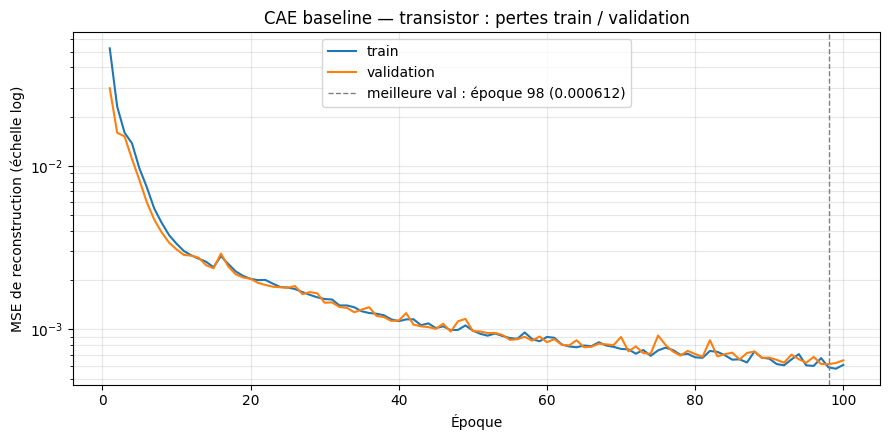

Fichiers dans l'Output :
  best_model.pt        3428.9 Ko
  history.csv             5.2 Ko
  loss_curves.png        66.1 Ko
  run_info.json           1.6 Ko


In [4]:
import platform
from datetime import datetime, timezone

import matplotlib.pyplot as plt

# ===== Courbes de perte =====
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(history_df["epoch"], history_df["train_loss"], label="train")
ax.plot(history_df["epoch"], history_df["val_loss"], label="validation")
ax.axvline(best_epoch, color="gray", linestyle="--", linewidth=1,
           label=f"meilleure val : époque {best_epoch} ({best_val_loss:.6f})")
ax.set_yscale("log")
ax.set_xlabel("Époque")
ax.set_ylabel("MSE de reconstruction (échelle log)")
ax.set_title(f"CAE baseline — {CATEGORY} : pertes train / validation")
ax.grid(True, which="both", alpha=0.3)
ax.legend()
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "loss_curves.png", dpi=120, bbox_inches="tight")
plt.show()

# ===== Informations d'exécution (source de la fiche d'expérience) =====
run_info = {
    "category": CATEGORY,
    "executed_at_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
    "code": {"repo": REPO_URL, "branch": REPO_BRANCH, "git_commit": GIT_COMMIT,
             "training_loop": "notebooks/06-cae-train.ipynb (cellule Entraînement)"},
    "environment": {"platform": "Kaggle", "python_version": sys.version.split()[0],
                    "torch_version": torch.__version__, "torchvision_version": torchvision.__version__,
                    "gpu": f"{torch.cuda.get_device_name(0)} (x{torch.cuda.device_count()})",
                    "os": platform.platform()},
    "data": {"dataset": "MVTec AD", "dataset_version": "ipythonx/mvtec-ad, Version 2",
             "split_manifest": f"docs/data/us-02-03/{CATEGORY}_manifest.csv",
             "train_images": len(train_ds), "val_images": len(val_ds), "test_used": False},
    "model": {"name": "cae_baseline_v1", "config_file": "experiments/configs/cae_baseline.json",
              "trainable_parameters": n_params},
    "training": {"epochs": EPOCHS, "batch_size": BATCH_SIZE, "learning_rate": LEARNING_RATE,
                 "optimizer": "Adam", "loss": "MSELoss", "image_size": list(CAE_CONFIG.image_size),
                 "seed": SEED, "num_workers": NUM_WORKERS},
    "results": {"best_epoch": int(best_epoch), "best_val_loss": best_val_loss,
                "final_train_loss": float(history_df.train_loss.iloc[-1]),
                "final_val_loss": float(history_df.val_loss.iloc[-1]),
                "training_time_min": round(TRAINING_TIME_S / 60, 1)},
    "artifacts": {"checkpoint": f"cae/{CATEGORY}/best_model.pt", "history": f"cae/{CATEGORY}/history.csv",
                  "loss_curves": f"cae/{CATEGORY}/loss_curves.png"},
}
(OUTPUT_DIR / "run_info.json").write_text(json.dumps(run_info, indent=2, ensure_ascii=False), "utf-8")

print("Fichiers dans l'Output :")
for f in sorted(OUTPUT_DIR.iterdir()):
    print(f"  {f.name:18s} {f.stat().st_size / 1e3:8.1f} Ko")